# 🌾 Crop Recommendation System — Machine Learning
**Dataset:** `Crop_recommendation.csv` (2200 rows × 8 columns)

**Features:** N, P, K (soil nutrients), temperature, humidity, ph, rainfall
**Target:** `label` — the crop to grow (22 crops)

**Pipeline:** Libraries → Load data → Data definition → Cleaning → Pre-processing → Feature engineering → Train 9 models → Prediction → Classification report → Accuracy comparison → Confusion matrix → Save model (`.pkl`)

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 9 Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier, ExtraTreesClassifier)
from sklearn.naive_bayes import GaussianNB

sns.set_style('whitegrid')
print('Libraries imported successfully')

Libraries imported successfully


## Step 2: Load the Dataset

In [2]:
df = pd.read_csv('Crop_recommendation.csv')
print('Dataset loaded. Shape:', df.shape)

Dataset loaded. Shape: (2200, 8)


## Step 3: Data Definition
### 3.1 First 5 rows

In [3]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


### 3.2 Last 5 rows

In [4]:
df.tail()

,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


### 3.3 Shape, columns and data types

In [5]:
print('Rows   :', df.shape[0])
print('Columns:', df.shape[1])
print('\nColumn names:', list(df.columns))
print('\nData types:\n', df.dtypes)

Rows   : 2200
Columns: 8

Column names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Data types:
 N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object


### 3.4 Info

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


### 3.5 Statistical summary

In [7]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


### 3.6 Target variable — crops and their counts

In [8]:
print('Number of unique crops:', df['label'].nunique())
print(df['label'].value_counts())

Number of unique crops: 22
label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64


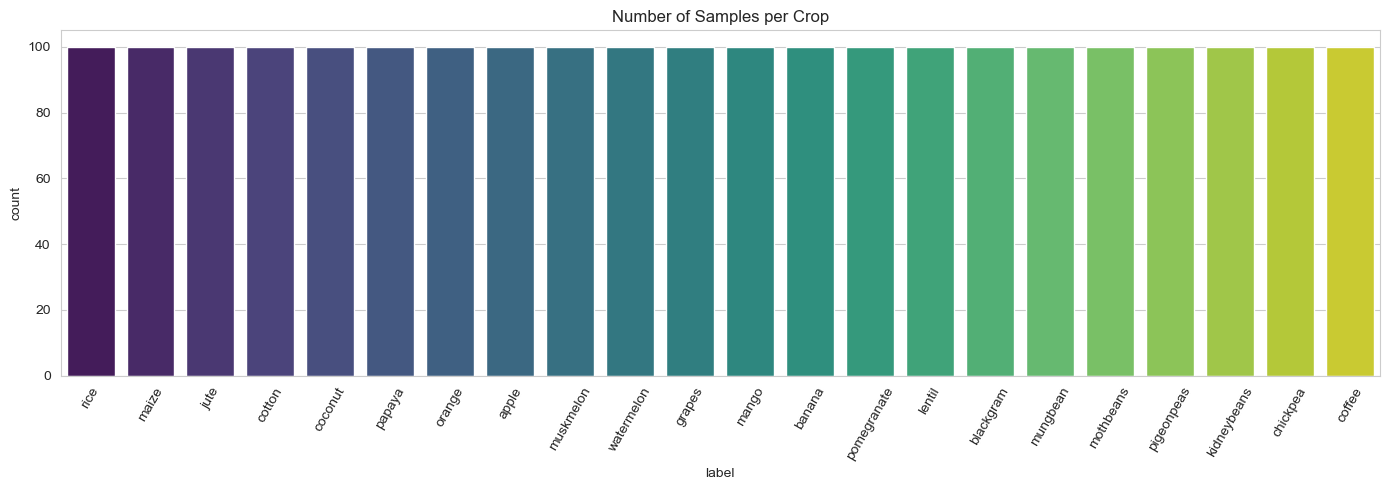

In [9]:
plt.figure(figsize=(14, 5))
sns.countplot(x='label', data=df, order=df['label'].value_counts().index, palette='viridis')
plt.title('Number of Samples per Crop')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

## Step 4: Data Cleaning

In [10]:
# 4.1 Missing values
print('Missing values per column:\n', df.isnull().sum())

Missing values per column:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [11]:
# 4.2 Duplicate rows
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()
print('Shape after removing duplicates:', df.shape)

Duplicate rows: 0
Shape after removing duplicates: (2200, 8)


In [12]:
# 4.3 Clean the label column (strip spaces, lowercase)
df['label'] = df['label'].str.strip().str.lower()

# 4.4 Remove impossible values (negative nutrients/rainfall, pH outside 0-14, humidity outside 0-100)
before = len(df)
df = df[(df[['N', 'P', 'K', 'rainfall']] >= 0).all(axis=1)]
df = df[(df['ph'].between(0, 14)) & (df['humidity'].between(0, 100))]
print('Invalid rows removed:', before - len(df))

Invalid rows removed: 0


N           : 0 outliers
P           : 138 outliers
K           : 200 outliers
temperature : 86 outliers
humidity    : 30 outliers
ph          : 57 outliers
rainfall    : 100 outliers


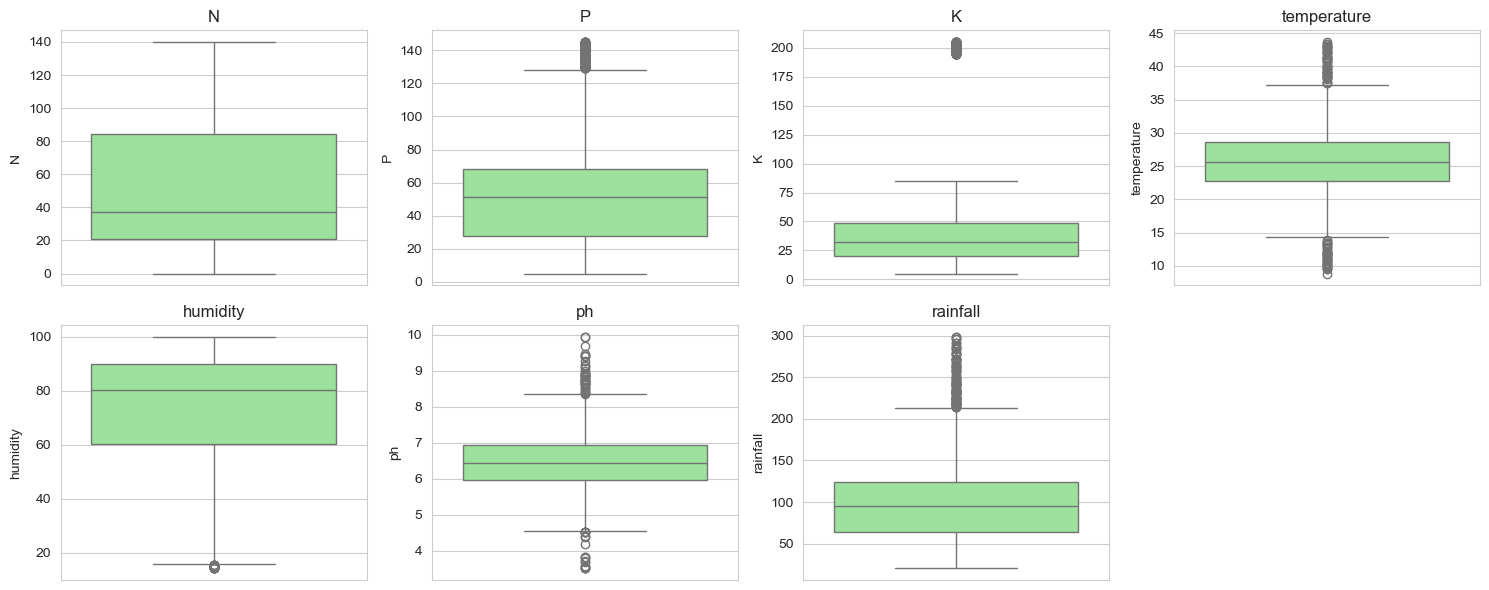

In [13]:
# 4.5 Outlier check (IQR) — we only REPORT outliers, not remove them,
# because extreme values are real for some crops (e.g. high K for grapes/apple, high rainfall for rice)
num_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
for col in num_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    out = ((df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)).sum()
    print(f'{col:12s}: {out} outliers')

plt.figure(figsize=(15, 6))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col], color='lightgreen')
    plt.title(col)
plt.tight_layout()
plt.show()

## Step 5: Data Pre-processing (EDA + Encoding)

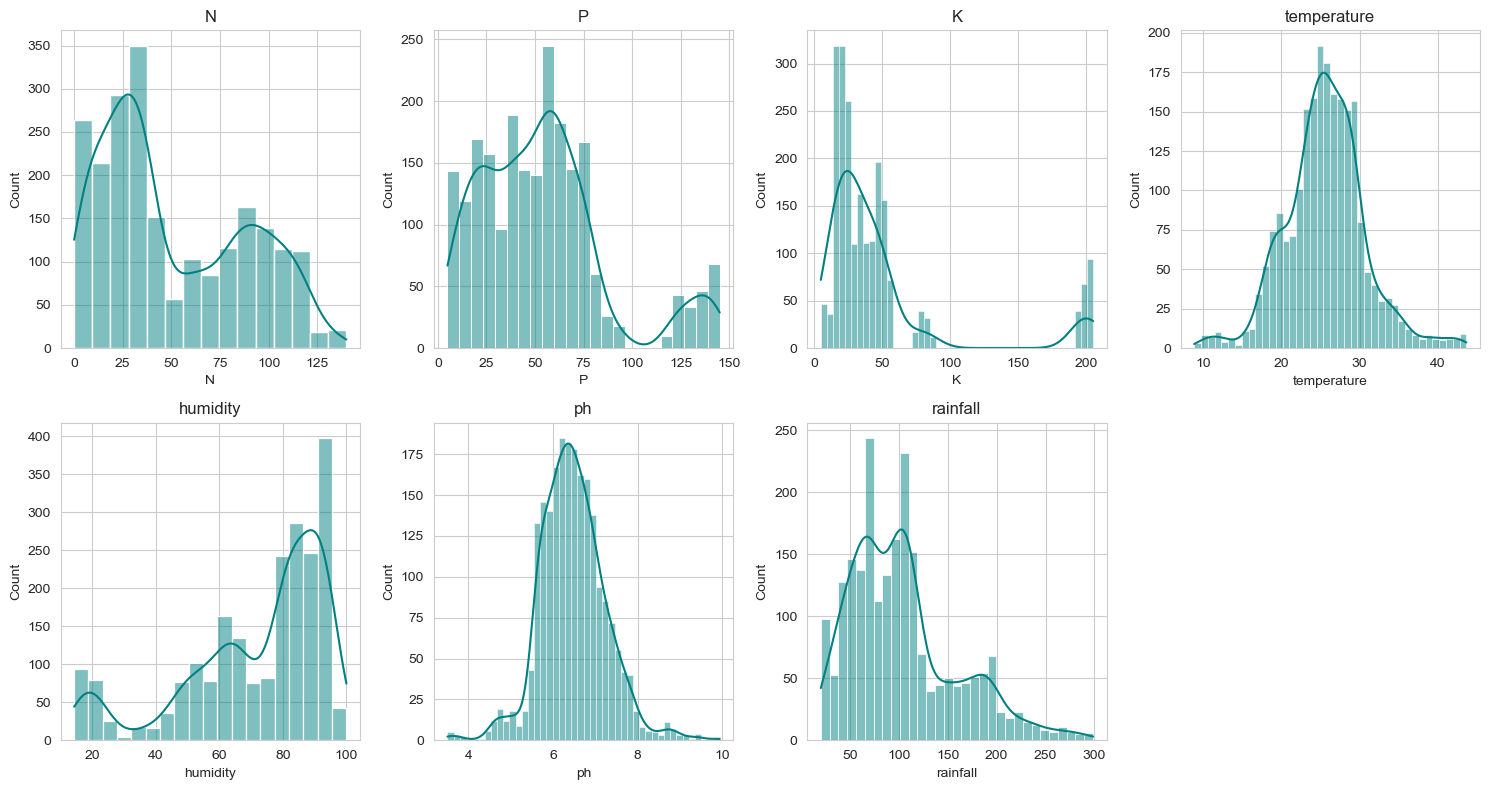

In [14]:
# 5.1 Distribution of each feature
plt.figure(figsize=(15, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 4, i)
    sns.histplot(df[col], kde=True, color='teal')
    plt.title(col)
plt.tight_layout()
plt.show()

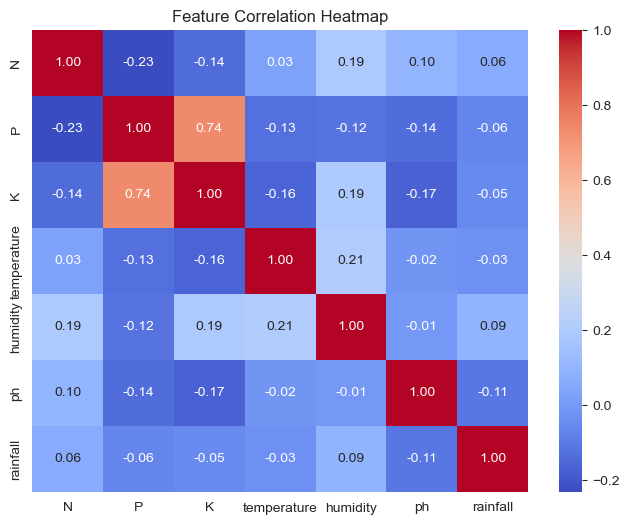

In [15]:
# 5.2 Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

In [16]:
# 5.3 Average feature values for each crop
df.groupby('label')[num_cols].mean().round(2)

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.80,134.22,199.89,22.63,92.33,5.93,112.65
banana,100.23,82.01,50.05,27.38,80.36,5.98,104.63
blackgram,40.02,67.47,19.24,29.97,65.12,7.13,67.88
chickpea,40.09,67.79,79.92,18.87,16.86,7.34,80.06
coconut,21.98,16.93,30.59,27.41,94.84,5.98,175.69
coffee,101.20,28.74,29.94,25.54,58.87,6.79,158.07
cotton,117.77,46.24,19.56,23.99,79.84,6.91,80.40
grapes,23.18,132.53,200.11,23.85,81.88,6.03,69.61
jute,78.40,46.86,39.99,24.96,79.64,6.73,174.79


In [17]:
# 5.4 Encode the target (crop name -> number)
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

{'apple': np.int64(0), 'banana': np.int64(1), 'blackgram': np.int64(2), 'chickpea': np.int64(3), 'coconut': np.int64(4), 'coffee': np.int64(5), 'cotton': np.int64(6), 'grapes': np.int64(7), 'jute': np.int64(8), 'kidneybeans': np.int64(9), 'lentil': np.int64(10), 'maize': np.int64(11), 'mango': np.int64(12), 'mothbeans': np.int64(13), 'mungbean': np.int64(14), 'muskmelon': np.int64(15), 'orange': np.int64(16), 'papaya': np.int64(17), 'pigeonpeas': np.int64(18), 'pomegranate': np.int64(19), 'rice': np.int64(20), 'watermelon': np.int64(21)}


## Step 6: Feature Engineering
New features created from the raw values:
- **NPK_sum** – total nutrient level
- **N_P_ratio, N_K_ratio, P_K_ratio** – nutrient balance
- **temp_humidity** – interaction between temperature and humidity
- **ph_category** – acidic (0) / neutral (1) / alkaline (2)

In [18]:
def add_features(data):
    data = data.copy()
    data['NPK_sum'] = data['N'] + data['P'] + data['K']
    data['N_P_ratio'] = data['N'] / (data['P'] + 1)
    data['N_K_ratio'] = data['N'] / (data['K'] + 1)
    data['P_K_ratio'] = data['P'] / (data['K'] + 1)
    data['temp_humidity'] = data['temperature'] * data['humidity'] / 100
    data['ph_category'] = np.where(data['ph'] < 6.5, 0, np.where(data['ph'] <= 7.5, 1, 2))
    return data

df_fe = add_features(df)
FEATURES = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall',
            'NPK_sum', 'N_P_ratio', 'N_K_ratio', 'P_K_ratio', 'temp_humidity', 'ph_category']
df_fe[FEATURES].head()

,N,P,K,temperature,humidity,ph,rainfall,NPK_sum,N_P_ratio,N_K_ratio,P_K_ratio,temp_humidity,ph_category
0,90,42,43,20.879744,82.002744,6.502985,202.935536,175,2.093023,2.045455,0.954545,17.121963,1
1,85,58,41,21.770462,80.319644,7.038096,226.655537,184,1.440678,2.023810,1.380952,17.485957,1
2,60,55,44,23.004459,82.320763,7.840207,263.964248,159,1.071429,1.333333,1.222222,18.937446,2
3,74,35,40,26.491096,80.158363,6.980401,242.864034,149,2.055556,1.804878,0.853659,21.234829,1
4,78,42,42,20.130175,81.604873,7.628473,262.717340,162,1.813953,1.813953,0.976744,16.427204,2


In [19]:
# Split features / target
X = df_fe[FEATURES]
y = df_fe['label_encoded']

# Train-test split (80/20, stratified so every crop appears in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (1760, 13)  Test: (440, 13)


## Step 7: Model Training — 9 Machine Learning Models

In [20]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'KNN':                 KNeighborsClassifier(n_neighbors=5),
    'SVM':                 SVC(kernel='rbf', probability=True, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42),
    'Naive Bayes':         GaussianNB(),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=42),
    'AdaBoost':            AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=5),
                                              n_estimators=100, random_state=42),
    'Extra Trees':         ExtraTreesClassifier(n_estimators=200, random_state=42),
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f'Trained: {name}')

Trained: Logistic Regression
Trained: KNN
Trained: SVM
Trained: Decision Tree
Trained: Random Forest
Trained: Naive Bayes
Trained: Gradient Boosting
Trained: AdaBoost
Trained: Extra Trees


## Step 8: Prediction

In [21]:
predictions = {}
train_acc, test_acc = {}, {}
for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    train_acc[name] = accuracy_score(y_train, model.predict(X_train_scaled))
    test_acc[name] = accuracy_score(y_test, y_pred)

# Sample: actual vs predicted (Random Forest)
sample = pd.DataFrame({
    'Actual': le.inverse_transform(y_test[:10]),
    'Predicted': le.inverse_transform(predictions['Random Forest'][:10])
})
sample

,Actual,Predicted
0,orange,orange
1,banana,banana
2,cotton,cotton
3,maize,maize
4,orange,orange
5,chickpea,chickpea
6,rice,rice
7,blackgram,blackgram
8,banana,banana
9,orange,orange


## Step 9: Classification Report (all 9 models)

In [22]:
for name, y_pred in predictions.items():
    print('=' * 65)
    print(f'{name}  —  Accuracy: {test_acc[name]*100:.2f}%')
    print('=' * 65)
    print(classification_report(y_test, y_pred, target_names=le.classes_))

Logistic Regression  —  Accuracy: 97.27%
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.91      1.00      0.95        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.95      1.00      0.98        20
      coffee       1.00      1.00      1.00        20
      cotton       0.91      1.00      0.95        20
      grapes       1.00      1.00      1.00        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       0.94      0.85      0.89        20
       maize       1.00      0.90      0.95        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      0.95      0.95        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      0.95      0

## Step 10: Accuracy Comparison

In [23]:
# 5-fold cross-validation for a more reliable score
cv_scores = {}
for name, model in models.items():
    cv_scores[name] = cross_val_score(model, scaler.transform(X), y, cv=5).mean()

results = pd.DataFrame({
    'Train Accuracy (%)': pd.Series(train_acc) * 100,
    'Test Accuracy (%)':  pd.Series(test_acc) * 100,
    'CV Accuracy (%)':    pd.Series(cv_scores) * 100,
}).round(2).sort_values('Test Accuracy (%)', ascending=False)
results

,Train Accuracy (%),Test Accuracy (%),CV Accuracy (%)
AdaBoost,100.00,99.55,99.00
Random Forest,100.00,99.32,99.32
Naive Bayes,98.86,99.09,98.86
Extra Trees,100.00,99.09,98.95
Gradient Boosting,100.00,98.64,98.82
SVM,98.30,98.18,97.86
Decision Tree,100.00,97.50,98.41
Logistic Regression,98.07,97.27,97.05
KNN,98.01,96.82,96.18


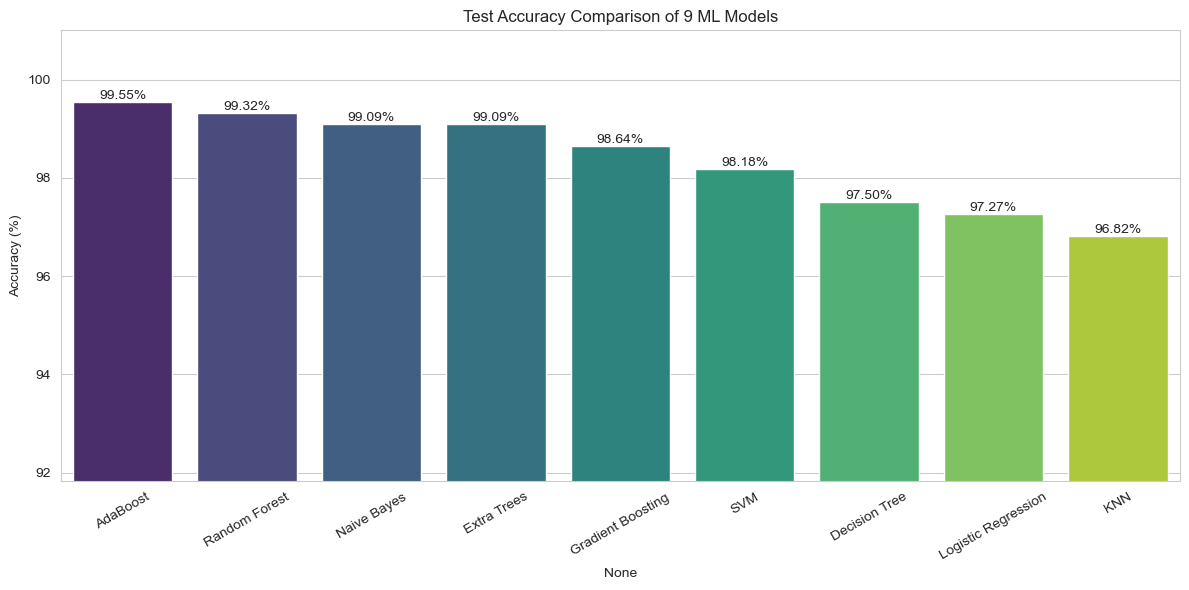

In [24]:
# Bar graph — test accuracy of each model
plt.figure(figsize=(12, 6))
ax = sns.barplot(x=results.index, y=results['Test Accuracy (%)'], palette='viridis')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.title('Test Accuracy Comparison of 9 ML Models')
plt.ylabel('Accuracy (%)')
plt.ylim(min(results['Test Accuracy (%)']) - 5, 101)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

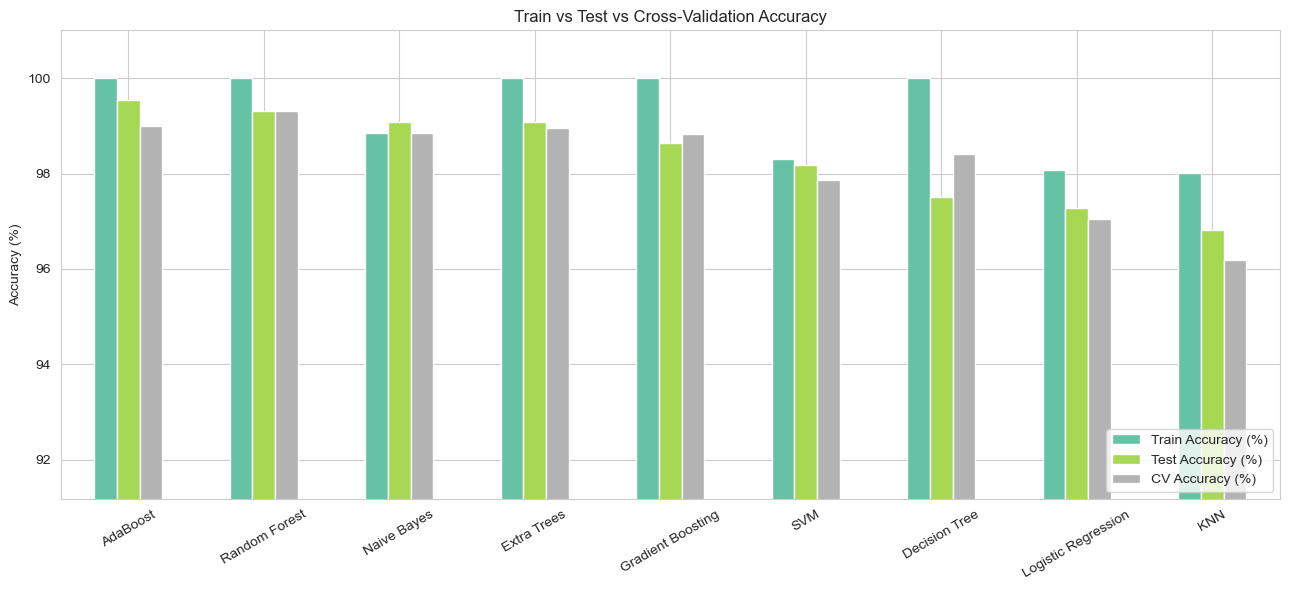

In [25]:
# Grouped bar graph — train vs test vs cross-validation
results.plot(kind='bar', figsize=(13, 6), colormap='Set2')
plt.title('Train vs Test vs Cross-Validation Accuracy')
plt.ylabel('Accuracy (%)')
plt.ylim(min(results.min()) - 5, 101)
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Step 11: Confusion Matrix

Best model: Random Forest


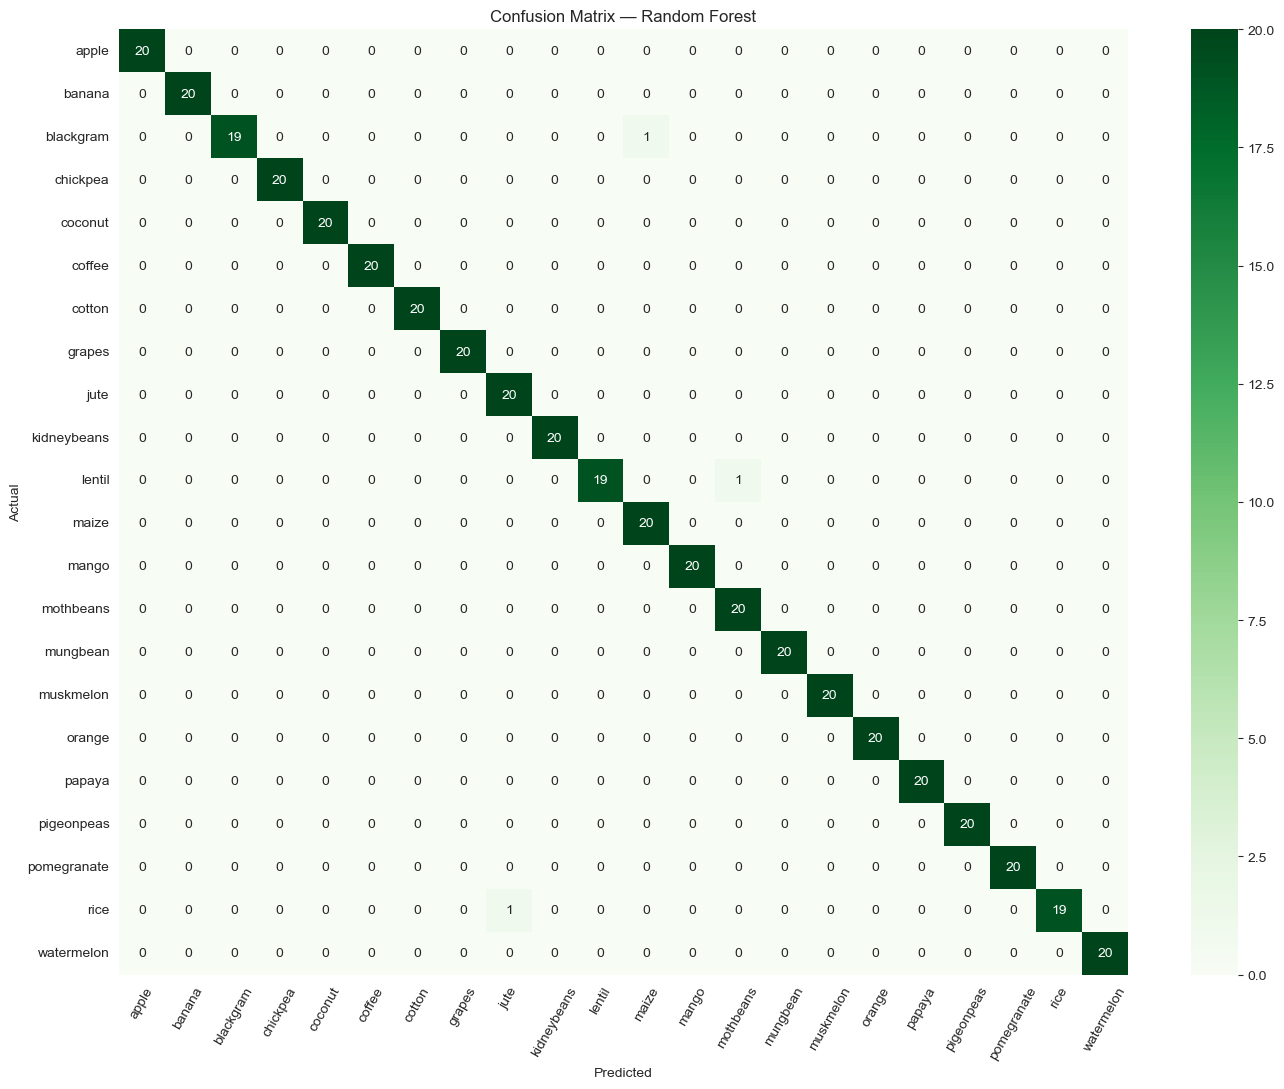

In [26]:
# Confusion matrix of the BEST model (chosen by cross-validation accuracy — most reliable)
best_name = results['CV Accuracy (%)'].idxmax()
print('Best model:', best_name)
cm = confusion_matrix(y_test, predictions[best_name])

plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Confusion Matrix — {best_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

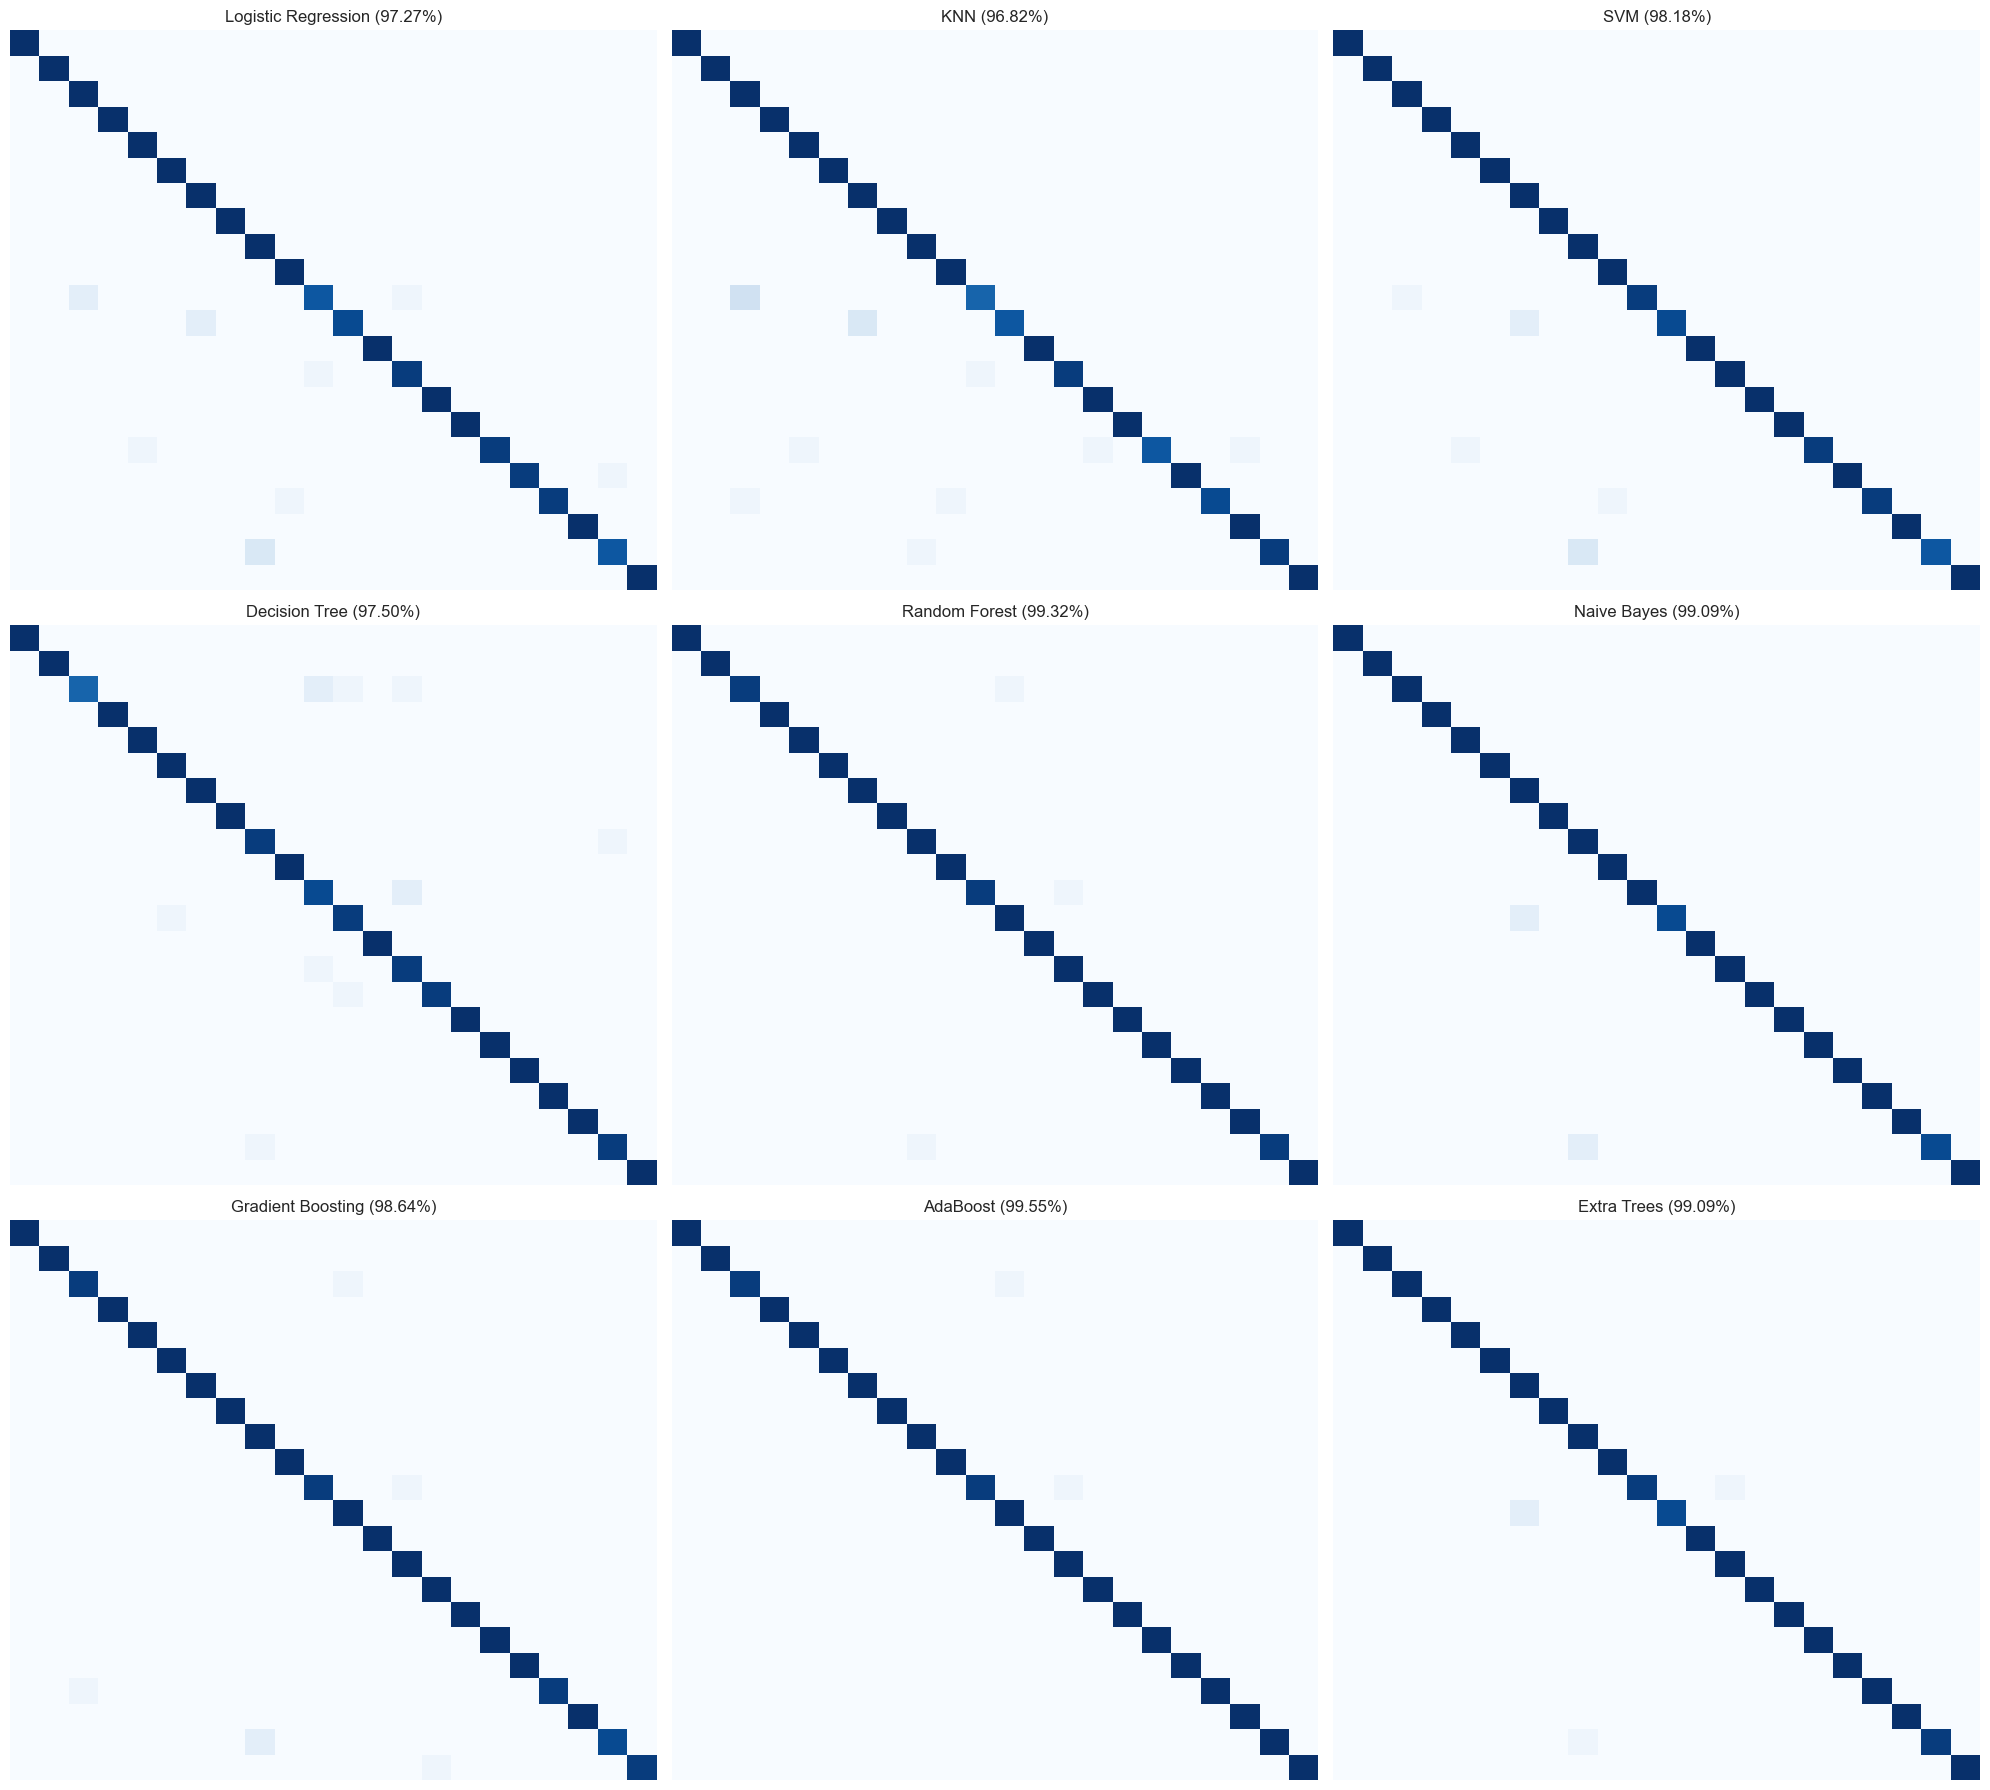

In [27]:
# Confusion matrices of all 9 models (small grid)
fig, axes = plt.subplots(3, 3, figsize=(20, 18))
for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), cmap='Blues', cbar=False, ax=ax,
                xticklabels=False, yticklabels=False)
    ax.set_title(f'{name} ({test_acc[name]*100:.2f}%)')
plt.tight_layout()
plt.show()

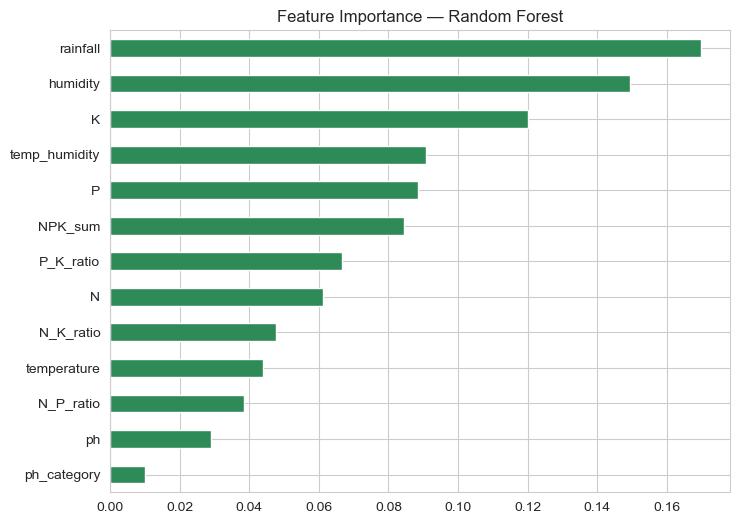

In [28]:
# Feature importance (Random Forest)
imp = pd.Series(trained_models['Random Forest'].feature_importances_, index=FEATURES).sort_values()
imp.plot(kind='barh', figsize=(8, 6), color='seagreen')
plt.title('Feature Importance — Random Forest')
plt.show()

## Step 12: Save the Best Model as a `.pkl` file (for app.py)

In [29]:
# Bundle model + scaler + label encoder + feature list in ONE file
bundle = {
    'model': trained_models[best_name],
    'model_name': best_name,
    'scaler': scaler,
    'label_encoder': le,
    'features': FEATURES,
    'accuracy': test_acc[best_name],
}
joblib.dump(bundle, 'crop_recommendation_model.pkl')
print(f'Saved crop_recommendation_model.pkl  (model: {best_name}, accuracy: {test_acc[best_name]*100:.2f}%)')

Saved crop_recommendation_model.pkl  (model: Random Forest, accuracy: 99.32%)


## Step 13: Test the Saved Model (manual prediction)

In [30]:
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):
    b = joblib.load('crop_recommendation_model.pkl')
    row = pd.DataFrame([[N, P, K, temperature, humidity, ph, rainfall]],
                       columns=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'])
    row = add_features(row)[b['features']]
    pred = b['model'].predict(b['scaler'].transform(row))
    return b['label_encoder'].inverse_transform(pred)[0]

print('Recommended crop:', recommend_crop(90, 42, 43, 20.88, 82.0, 6.5, 202.9))   # expected: rice
print('Recommended crop:', recommend_crop(20, 130, 200, 23.0, 92.0, 5.9, 110.0))  # expected: apple

Recommended crop: rice
Recommended crop: apple
